In [1]:
import torch
import torch.nn as nn 
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import copy
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve)
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
SEED = 42 
torch.manual_seed(SEED) 
np.random.seed(SEED) 

device = torch.device("cuda" if torch.cuda.is_available() else "cpu") 
print(device)

cuda


In [3]:
df = pd.read_csv("data_app.csv")

# Drop the unnamed index column if present 
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

feature_cols = [c for c in df.columns if c.startswith("var_")]

# Split rows by outcome
# ----------------------------
#Labelled rows - we know the outcomes
df_good = df[df["Good"] == 1].copy()
df_bad = df[df["Bad"] == 1].copy()

df_reject = df[df["Reject"] == 1].copy()
df_ntu = df[df["NTU"] == 1].copy()

df_labelled = pd.concat([df_good, df_bad], ignore_index=True)

X_reject = df_reject[feature_cols].values.astype(np.float32)
X_ntu = df_ntu[feature_cols].values.astype(np.float32)

X_labelled = df_labelled[feature_cols].values.astype(np.float32)
y_labelled = df_labelled["Bad"].values.astype(np.int64)

df_unlabelled = pd.concat([df_reject, df_ntu], ignore_index=True)
X_unlabelled = df_unlabelled[feature_cols].values.astype(np.float32)

# Model Architecture

In [4]:
class CreditNN(nn.Module):
    """
    Binary classifier: Good (0) vs Bad (1).
    Uses Sigmoid on the final neuron - appropriate for binary output.
    The network outputs a single probability P(Bad)
    """
    def __init__(self, input_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64), # (First linear Layer) - Input layer to hidden layer with 64 neurons
            nn.Sigmoid(), # (First activation function) - Hidden layer activation
            nn.Linear(64, 32), # (Second linear Layer) - Hidden layer with 32 neurons
            nn.Sigmoid(), # (Second activation function) - Hidden layer activation
            nn.Linear(32, 16), # (Third linear Layer) - Hidden layer with 16 neurons
            nn.Sigmoid(), # (Third activation function) - Hidden layer activation
            nn.Linear(16, 1))  # single output '1': logit for P(Bad) ; (Final linear Layer)

    def forward(self, x):
        return self.net(x) # returns raw logit - then we apply BCEWithLogitsLoss

class CreditDataset(Dataset): # this function just stores the dataframe in a way that pytorch can use it
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self) : return len(self.X)

    def __getitem__(self, idx) : return self.X[idx], self.y[idx]

In [5]:
def train_model(X_train, y_train, input_dim, X_val=None, y_val=None, epochs=40, lr=0.001):
    """
    Train a CreditNN on the provided data.
    Returns the trained model along with per-epoch loss and accuracy lists.
    """
    loader = DataLoader(
        CreditDataset(X_train, y_train),
        batch_size=120, shuffle=True
    )

    model = CreditNN(input_dim=input_dim).to(device)
    bad_count = (y_train == 1).sum()
    good_count = (y_train == 0).sum()

    weight_factor = 0.69

    pos_weight = torch.tensor([(good_count / bad_count) * weight_factor], dtype=torch.float32).to(device)

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer=optimizer, mode='min', factor=0.5, patience=5) 

    train_losses, train_accs = [], []
    val_losses, val_accs = [], []

    best_val_auc = -np.inf
    best_epoch = 0
    best_state = None

    # Optimization: Move validation tensor creation outside the loop once
    has_val = X_val is not None and y_val is not None
    if has_val:
        val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
        val_labels = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1).to(device)

    for epoch in range(epochs):
        model.train()
        running_loss = correct = total = 0

        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            optimizer.zero_grad()
            logits = model(inputs)
            loss = criterion(logits, labels) 
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            preds = (torch.sigmoid(logits) >= 0.5).long()
            correct += (preds == labels.long()).sum().item()
            total += labels.size(0)

        train_loss = running_loss / len(loader)
        train_acc = correct / total
        train_losses.append(train_loss)
        train_accs.append(train_acc)

        log_str = f"Epoch {epoch+1:3d}/{epochs} | train loss {train_loss:.4f} | train acc {train_acc:.4f}"

        # Validation logic
        if has_val:
            model.eval()
            with torch.no_grad():
                val_logits = model(val_tensor)
                val_loss = criterion(val_logits, val_labels)
                scheduler.step(val_loss.item())

                # Reuse sigmoid calculation once
                val_probs_tensor = torch.sigmoid(val_logits)
                val_preds = (val_probs_tensor >= 0.5).long()
                val_correct = (val_preds == val_labels.long()).sum().item()
                val_total = val_labels.size(0)

            val_loss_item = val_loss.item()
            val_acc_item = val_correct / val_total
            val_losses.append(val_loss_item)
            val_accs.append(val_acc_item)

            val_probs = val_probs_tensor.cpu().numpy().flatten() 
            val_auc = roc_auc_score(y_val, val_probs) 

            log_str += f" | val loss {val_loss_item:.4f} | val acc {val_acc_item:.4f} | val AUC {val_auc:.4f}"

            if val_auc > best_val_auc: 
                best_val_auc = val_auc 
                best_epoch = epoch + 1 
                best_state = copy.deepcopy(model.state_dict()) 

        # Single print call per epoch
        print(log_str)

    if best_state is not None: 
        model.load_state_dict(best_state) 
        print(f"\nRestored best model from epoch {best_epoch} with validation AUC = {best_val_auc:.4f}") 

    return (model, train_losses, train_accs, val_losses, val_accs, best_epoch, best_val_auc)

In [6]:
def get_probabilities(model, X: np.ndarray) -> np.ndarray:
    """
    Run inference on X and return P(Bad) for every row, shape (N,).
    """
    model.eval()
    tensor = torch.tensor(X, dtype=torch.float32).to(device)
    with torch.no_grad():
        logits = model(tensor)
        probs = torch.sigmoid(logits).cpu().numpy().flatten()
    return probs

def evaluate_model(model, X, y, name="Model", threshold=0.5, train_losses=None, train_accs=None, val_losses=None, val_accs=None, best_epoch=None):
    """
    Full evaluation: classification report, confusion matrix, AUC, ROC curve.
    Returns (y_pred, p_bad) for further use.
    """

    p_bad = get_probabilities(model, X)
    y_pred = (p_bad >= threshold).astype(int)

    # Classification report
    print(classification_report(y, y_pred, target_names=["Good", "Bad"], zero_division=0))

    # AUC
    if len(np.unique(y)) > 1:
        auc_score = roc_auc_score(y, p_bad)
        print(f"ROC-AUC : {auc_score:.4f}")
    else:
        auc_score = False
        print(f"ROC-AUC : cannot compute (only one class in y)")

    # Plots 
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(name, fontsize=13)

    #Loss & Accuracy curves
    axs[0].plot(losses_base, label="Train loss", color="#2196F3")
    axs[0].plot(val_losses_base, label="Val loss", color="#F44336", linestyle="--")
    axs[0].plot(accs_base, label="Train acc", color="#4CAF50")
    axs[0].plot(val_accs_base, label="Val acc", color="#FF9800", linestyle="--")

    # Mark the best validation epoch
    if best_epoch is not None:
        axs[0].axvline(x=best_epoch-1, color="gray", linestyle="--", alpha=0.5)
        axs[0].text(best_epoch-1, axs[0].get_ylim()[1]*0.95, f"Best val epoch: {best_epoch}", rotation=90, verticalalignment="top", fontsize=8)

    axs[0].set_title("Loss & Accuracy per Epoch")
    axs[0].set_xlabel("Epoch")
    axs[0].legend(fontsize=8)
    axs[0].grid(linestyle="--", alpha=0.4)

    # Confusion matrix
    cm = confusion_matrix(y, y_pred=y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axs[1],
                xticklabels=["Good", "Bad"],
                yticklabels=["Good", "Bad"])
    axs[1].set_title("Confusion Matrix")
    axs[1].set_xlabel("Predicted")
    axs[1].set_ylabel("True")

    # ROC curve
    if auc_score is not None:
        fpr, tpr, _ = roc_curve(y, p_bad)
        axs[2].plot(fpr, tpr, color="#2196F3",
                    label=f"AUC = {auc_score:.4f}", linewidth=2)
        axs[2].plot([0, 1], [0, 1], "k--", linewidth=1)
        axs[2].fill_between(fpr, tpr, alpha=0.1, color="#2196F3")
        axs[2].set_title("ROC Curve")
        axs[2].set_xlabel("False Positive Rate")
        axs[2].set_ylabel("True Positive Rate")
        axs[2].legend()
        axs[2].grid(linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

    return y_pred, p_bad

# Train - test splitting of the data

In [7]:
X_train_base, X_test, y_train_base, y_test = train_test_split(X_labelled, y_labelled, test_size=0.067,
    random_state=SEED, stratify=y_labelled if len(np.unique(y_labelled)) > 1 else None) # stratify = 2

X_train, X_val, y_train, y_val = train_test_split(X_train_base, y_train_base, test_size=0.067,
    random_state=SEED, stratify=y_train_base if len(np.unique(y_train_base)) > 1 else None) # stratify = 2

In [8]:
from sklearn.ensemble import RandomForestClassifier 

rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

importance = rf.feature_importances_
topn = min(150, len(importance))

selected_idx = np.argsort(importance)[::-1][:topn]

X_train = X_train[:, selected_idx] 
X_val = X_val[:, selected_idx] 
X_test = X_test[:, selected_idx] 
X_reject = X_reject[:, selected_idx] 
X_ntu = X_ntu[:, selected_idx] 
X_unlabelled = X_unlabelled[:, selected_idx] 
X_labelled = X_labelled[:, selected_idx] 

feature_cols = [feature_cols[i] for i in selected_idx]

In [9]:
from sklearn.metrics import (precision_score, recall_score, f1_score, confusion_matrix) 

input_dim = X_labelled.shape[1]

(model_base, losses_base, accs_base, val_losses_base, val_accs_base, best_epoch_base, best_valauc_base) = train_model(
    X_train,
    y_train, 
    input_dim, 
    X_val=X_val, 
    y_val=y_val)

print("Best epoch:", best_epoch_base) 
print("Best validation AUC:", best_valauc_base)

Epoch   1/40 | train loss 0.8111 | train acc 0.7858 | val loss 0.7088 | val acc 0.7270 | val AUC 0.8347
Epoch   2/40 | train loss 0.6798 | train acc 0.7725 | val loss 0.6827 | val acc 0.7824 | val AUC 0.8433
Epoch   3/40 | train loss 0.6678 | train acc 0.7789 | val loss 0.6817 | val acc 0.7658 | val AUC 0.8417
Epoch   4/40 | train loss 0.6647 | train acc 0.7827 | val loss 0.6733 | val acc 0.7715 | val AUC 0.8460
Epoch   5/40 | train loss 0.6601 | train acc 0.7847 | val loss 0.6740 | val acc 0.7834 | val AUC 0.8452
Epoch   6/40 | train loss 0.6589 | train acc 0.7853 | val loss 0.6776 | val acc 0.8057 | val AUC 0.8443
Epoch   7/40 | train loss 0.6579 | train acc 0.7866 | val loss 0.6746 | val acc 0.7909 | val AUC 0.8446
Epoch   8/40 | train loss 0.6578 | train acc 0.7869 | val loss 0.6697 | val acc 0.7873 | val AUC 0.8461
Epoch   9/40 | train loss 0.6580 | train acc 0.7855 | val loss 0.6696 | val acc 0.7855 | val AUC 0.8455
Epoch  10/40 | train loss 0.6545 | train acc 0.7877 | val loss 0

              precision    recall  f1-score   support

        Good       0.94      0.77      0.85      3235
         Bad       0.39      0.76      0.52       630

    accuracy                           0.77      3865
   macro avg       0.67      0.76      0.68      3865
weighted avg       0.85      0.77      0.79      3865

ROC-AUC : 0.8499


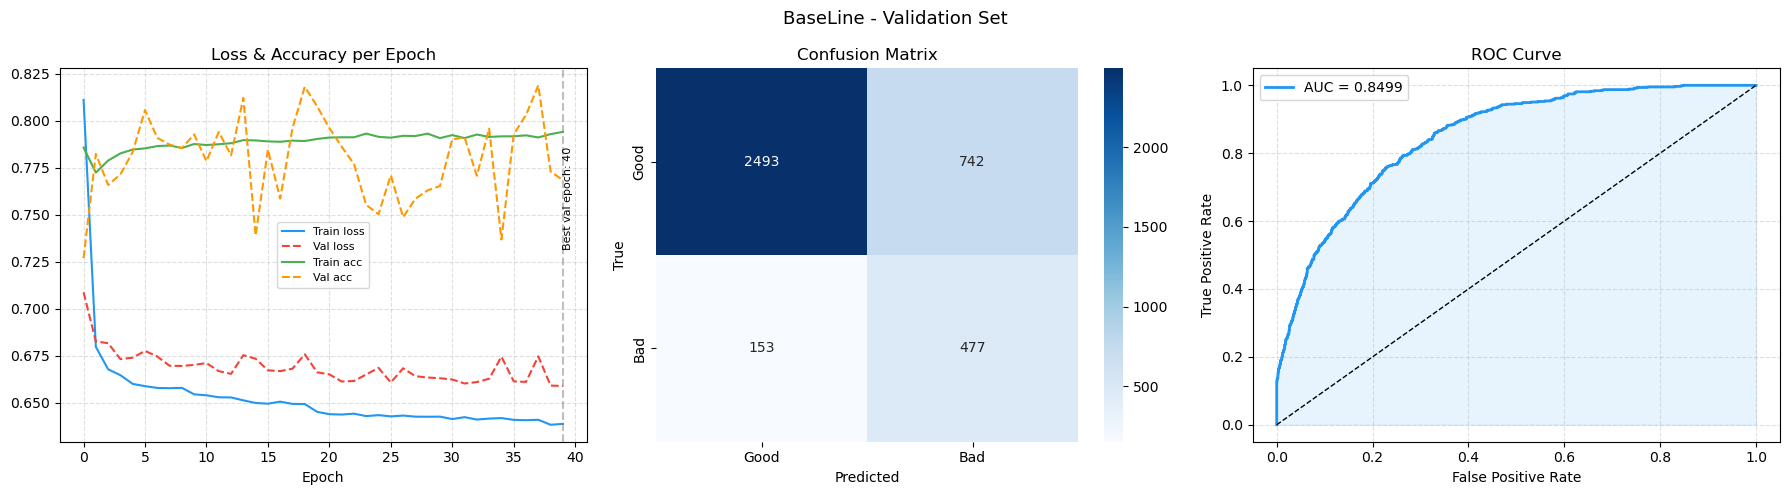

              precision    recall  f1-score   support

        Good       0.94      0.79      0.86      3466
         Bad       0.41      0.74      0.53       676

    accuracy                           0.78      4142
   macro avg       0.67      0.77      0.69      4142
weighted avg       0.85      0.78      0.81      4142

ROC-AUC : 0.8581


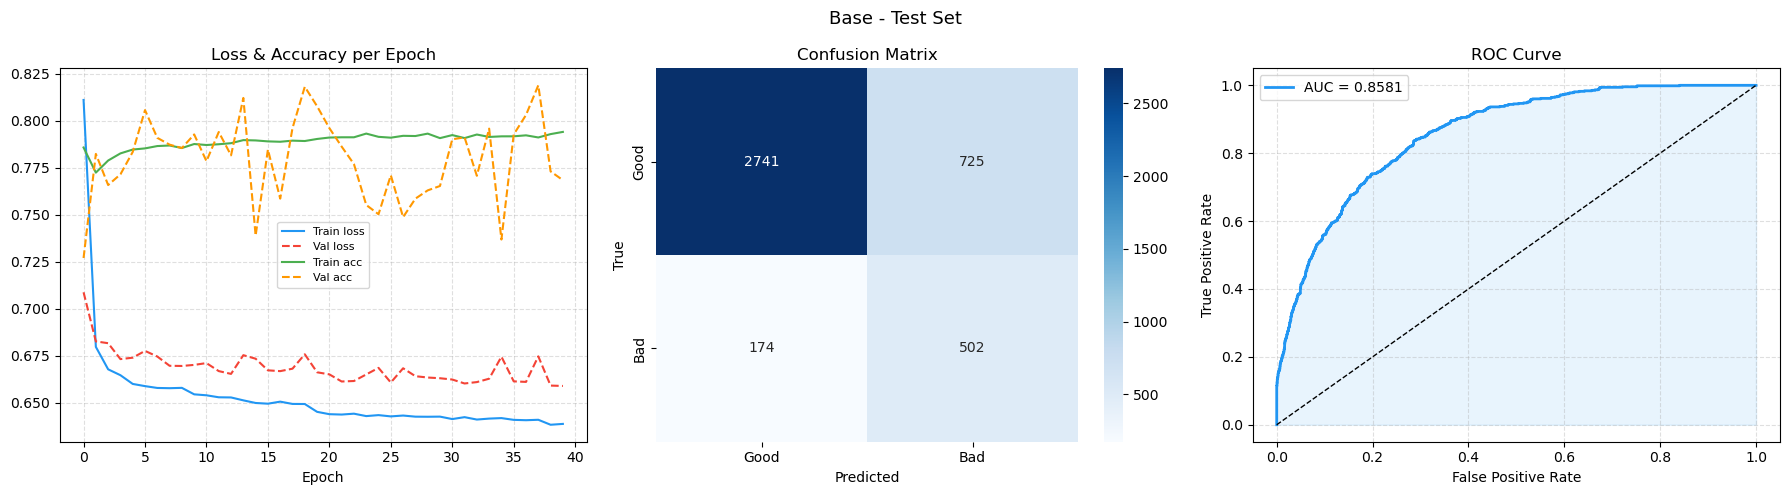

In [10]:
y_pred_val, prob_val = evaluate_model(model_base, X_val, y_val, name="BaseLine - Validation Set", threshold=0.5, train_losses=losses_base, train_accs=accs_base, val_losses=val_losses_base,val_accs=val_accs_base,best_epoch=best_epoch_base) 

y_pred_test, prob_test = evaluate_model(model_base, X_test, y_test, name="Base - Test Set", threshold=0.5) 

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

logreg_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        random_state=SEED,
        class_weight="balanced",
        max_iter=5000
    ))
])

logreg_model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [12]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

def evaluate_logistic(model, X, y, name="Logistic Regression"):

    p_bad = model.predict_proba(X)[:, 1]
    y_pred = (p_bad >= 0.5).astype(int)

    print("\n", name)
    print(classification_report(
        y,
        y_pred,
        target_names=["Good", "Bad"],
        zero_division=0
    ))

    auc_score = roc_auc_score(y, p_bad)

    print(f"ROC-AUC: {auc_score:.4f}")

    cm = confusion_matrix(y, y_pred)

    plt.figure(figsize=(6,5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Good","Bad"],
        yticklabels=["Good","Bad"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    return y_pred, p_bad, auc_score


 Logistic Regression - Validation Set
              precision    recall  f1-score   support

        Good       0.95      0.73      0.82      3235
         Bad       0.36      0.78      0.49       630

    accuracy                           0.74      3865
   macro avg       0.65      0.76      0.66      3865
weighted avg       0.85      0.74      0.77      3865

ROC-AUC: 0.8460


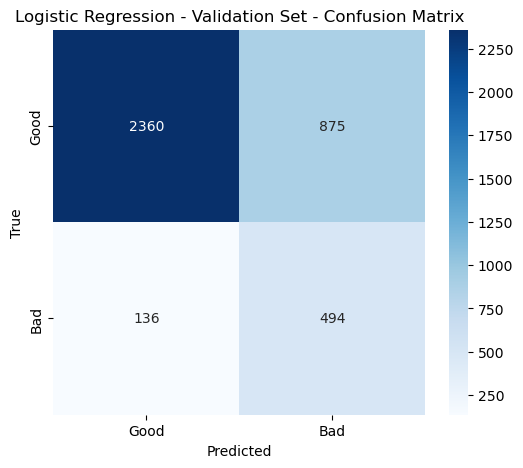


 Logistic Regression - Test Set
              precision    recall  f1-score   support

        Good       0.95      0.75      0.84      3466
         Bad       0.38      0.79      0.51       676

    accuracy                           0.75      4142
   macro avg       0.66      0.77      0.67      4142
weighted avg       0.86      0.75      0.78      4142

ROC-AUC: 0.8547


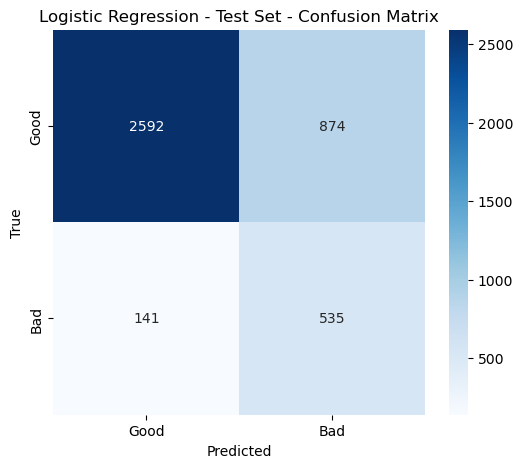

In [13]:
y_pred_lr_val, prob_lr_val, auc_lr_val = evaluate_logistic(
    logreg_model,
    X_val,
    y_val,
    "Logistic Regression - Validation Set")

y_pred_lr_test, prob_lr_test, auc_lr_test = evaluate_logistic(
    logreg_model,
    X_test,
    y_test,
    "Logistic Regression - Test Set")

In [14]:
prob_reject_base = get_probabilities(
    model_base, 
    X_reject
)

prob_ntu_base = get_probabilities(
    model_base, 
    X_ntu
)

print(
    "Reject Base P(Bad):",
    "\n",
    prob_reject_base.min(),
    "\n",
    prob_reject_base.mean(),
    "\n",
    prob_reject_base.max()
)

print("\n","="*50,"\n","\n","NTU Base P(Bad):",
    "\n",
    prob_ntu_base.min(),
    "\n",
    prob_ntu_base.mean(),
    "\n",
    prob_ntu_base.max()
)

Reject Base P(Bad): 
 0.0044366852 
 0.6299544 
 0.980555

 
 NTU Base P(Bad): 
 0.0044482294 
 0.43091094 
 0.95462286


# Dataset class that also contains the weights that we would need to Reject Inference methods 

In [15]:
class CreditDatasetWeighted(Dataset):

    def __init__(self, X, y, weights):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y,dtype=torch.float32)
        self.weights = torch.tensor(weights,dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return (
            self.X[idx],
            self.y[idx],
            self.weights[idx])


# Implementation of Fuzzy Augmentation for predicting the Rejects/NTUs

In [16]:
def create_fuzzy_augmented_data(
    X_accepted,
    y_accepted,
    X_unlabelled,
    p_bad_unlabelled
):

    # --------------------------------------------------
    # Accepted applicants
    # --------------------------------------------------

    X_accept = X_accepted.copy()

    y_accept = y_accepted.astype(np.float32)

    # Every observed Good/Bad applicant has full weight
    w_accept = np.ones(
        len(X_accept),
        dtype=np.float32
    )

    # --------------------------------------------------
    # Fuzzy representation of rejects/NTUs
    # --------------------------------------------------

    # Each applicant appears twice:
    #
    # Good version: weight = 1 - P(Bad)
    # Bad version : weight = P(Bad)

    X_fuzzy = np.repeat(
        X_unlabelled,
        2,
        axis=0
    )

    y_fuzzy = np.tile(
        np.array([0, 1], dtype=np.float32),
        len(X_unlabelled)
    )

    w_fuzzy = np.empty(
        len(X_unlabelled) * 2,
        dtype=np.float32
    )

    w_fuzzy[0::2] = 1.0 - p_bad_unlabelled
    w_fuzzy[1::2] = p_bad_unlabelled

    # --------------------------------------------------
    # Combine
    # --------------------------------------------------

    X_augmented = np.vstack([
        X_accept,
        X_fuzzy
    ])

    y_augmented = np.concatenate([
        y_accept,
        y_fuzzy
    ])

    weights_augmented = np.concatenate([
        w_accept,
        w_fuzzy
    ])

    return (
        X_augmented,
        y_augmented,
        weights_augmented
    )

In [17]:
def train_fuzzy_model(
    X_train,
    y_train,
    X_unlabelled,
    p_bad_unlabelled,
    input_dim,
    X_val=None,
    y_val=None,
    epochs=40,
    lr=0.001
):

    # ==================================================
    # 1. CREATE FUZZY AUGMENTED DATA
    # ==================================================

    (
        X_augmented,
        y_augmented,
        sample_weights
    ) = create_fuzzy_augmented_data(
        X_accepted=X_train,
        y_accepted=y_train,
        X_unlabelled=X_unlabelled,
        p_bad_unlabelled=p_bad_unlabelled
    )

    print(
        "Original training observations:",
        len(X_train)
    )

    print(
        "Unlabelled observations:",
        len(X_unlabelled)
    )

    print(
        "Fuzzy augmented observations:",
        len(X_augmented)
    )

    # ==================================================
    # 2. DATASET
    # ==================================================

    dataset = CreditDatasetWeighted(
        X_augmented,
        y_augmented,
        sample_weights
    )

    loader = DataLoader(
        dataset,
        batch_size=120,
        shuffle=True
    )

    # ==================================================
    # 3. MODEL
    # ==================================================

    model = CreditNN(
        input_dim=input_dim
    ).to(device)

    # ==================================================
    # 4. CLASS WEIGHT
    # ==================================================

    bad_count = np.sum(
        y_train == 1
    )

    good_count = np.sum(
        y_train == 0
    )

    weight_factor = 0.69

    pos_weight = torch.tensor(
        [
            (good_count / bad_count)
            * weight_factor
        ],
        dtype=torch.float32,
        device=device
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=pos_weight,
        reduction="none"
    )

    # ==================================================
    # 5. OPTIMIZER
    # ==================================================

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=5e-4
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer=optimizer,
        mode="min",
        factor=0.5,
        patience=5
    )

    # ==================================================
    # 6. TRACKING
    # ==================================================

    train_losses = []
    train_accs = []

    val_losses = []
    val_accs = []

    best_val_auc = -np.inf
    best_epoch = 0
    best_state = None

    # ==================================================
    # 7. VALIDATION TENSORS
    # ==================================================

    has_val = (
        X_val is not None
        and y_val is not None
    )

    if has_val:

        val_tensor = torch.tensor(
            X_val,
            dtype=torch.float32,
            device=device
        )

        val_labels = torch.tensor(
            y_val,
            dtype=torch.float32,
            device=device
        ).unsqueeze(1)

    # ==================================================
    # 8. TRAINING LOOP
    # ==================================================

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels, weights in loader:

            inputs = inputs.to(device)

            labels = (
                labels
                .float()
                .unsqueeze(1)
                .to(device)
            )

            weights = (
                weights
                .float()
                .unsqueeze(1)
                .to(device)
            )

            optimizer.zero_grad()

            logits = model(inputs)

            # Per-observation BCE loss
            loss_per_sample = criterion(
                logits,
                labels
            )

            # Apply fuzzy observation weights
            weighted_loss = (
                loss_per_sample
                * weights
            )

            loss = weighted_loss.mean()
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            
            preds = (
                torch.sigmoid(logits)
                >= 0.5
            ).long()

            correct += (
                preds == labels.long()
            ).sum().item()

            total += labels.size(0)

        train_loss = (
            running_loss / len(loader)
        )

        train_acc = (
            correct / total
        )

        train_losses.append(
            train_loss
        )

        train_accs.append(
            train_acc
        )

        log_str = (
            f"Epoch {epoch + 1:3d}/{epochs}"
            f" | train loss {train_loss:.4f}"
            f" | train acc {train_acc:.4f}"
        )

        # ==================================================
        # 9. VALIDATION
        # ==================================================

        if has_val:

            model.eval()

            with torch.no_grad():

                val_logits = model(
                    val_tensor
                )

                # Validation is NOT fuzzy.
                # These are real known Good/Bad observations.

                validation_criterion = (
                    nn.BCEWithLogitsLoss(
                        pos_weight=pos_weight
                    )
                )

                val_loss = validation_criterion(
                    val_logits,
                    val_labels
                )

                scheduler.step(
                    val_loss.item()
                )

                val_probs_tensor = torch.sigmoid(
                    val_logits
                )

                val_preds = (
                    val_probs_tensor >= 0.5
                ).long()

                val_acc = (
                    val_preds
                    == val_labels.long()
                ).float().mean().item()

            val_loss_item = val_loss.item()

            val_losses.append(
                val_loss_item
            )

            val_accs.append(
                val_acc
            )

            val_probs = (
                val_probs_tensor
                .cpu()
                .numpy()
                .flatten()
            )

            val_auc = roc_auc_score(
                y_val,
                val_probs
            )

            log_str += (
                f" | val loss {val_loss_item:.4f}"
                f" | val acc {val_acc:.4f}"
                f" | val AUC {val_auc:.4f}"
            )

            # Save best model based on validation AUC
            if val_auc > best_val_auc:

                best_val_auc = val_auc

                best_epoch = (
                    epoch + 1
                )

                best_state = copy.deepcopy(
                    model.state_dict()
                )

        print(log_str)

    # ==================================================
    # 10. RESTORE BEST MODEL
    # ==================================================

    if best_state is not None:

        model.load_state_dict(
            best_state
        )

        print(
            f"\nRestored best fuzzy model "
            f"from epoch {best_epoch} "
            f"with validation AUC = "
            f"{best_val_auc:.4f}"
        )

    return (
        model,
        train_losses,
        train_accs,
        val_losses,
        val_accs,
        best_epoch,
        best_val_auc
    )

In [18]:
X_ri = np.vstack([
    X_reject,
    X_ntu
])

p_bad_ri = np.concatenate([
    prob_reject_base,
    prob_ntu_base
])

In [19]:
(
    model_fuzzy,
    losses_fuzzy,
    accs_fuzzy,
    val_losses_fuzzy,
    val_accs_fuzzy,
    best_epoch_fuzzy,
    best_val_auc_fuzzy
) = train_fuzzy_model(
    X_train=X_train,
    y_train=y_train,
    X_unlabelled=X_ri,
    p_bad_unlabelled=p_bad_ri,
    input_dim=input_dim,
    X_val=X_val,
    y_val=y_val
)

Original training observations: 53813
Unlabelled observations: 138180
Fuzzy augmented observations: 330173
Epoch   1/40 | train loss 0.5294 | train acc 0.5234 | val loss 0.7747 | val acc 0.6820 | val AUC 0.8305
Epoch   2/40 | train loss 0.5037 | train acc 0.5344 | val loss 0.7158 | val acc 0.7457 | val AUC 0.8264
Epoch   3/40 | train loss 0.5025 | train acc 0.5340 | val loss 0.7329 | val acc 0.7154 | val AUC 0.8322
Epoch   4/40 | train loss 0.5014 | train acc 0.5341 | val loss 0.7619 | val acc 0.6758 | val AUC 0.8357
Epoch   5/40 | train loss 0.5012 | train acc 0.5343 | val loss 0.7598 | val acc 0.6859 | val AUC 0.8319
Epoch   6/40 | train loss 0.5008 | train acc 0.5345 | val loss 0.7236 | val acc 0.7128 | val AUC 0.8329
Epoch   7/40 | train loss 0.5003 | train acc 0.5346 | val loss 0.7855 | val acc 0.6572 | val AUC 0.8362
Epoch   8/40 | train loss 0.5001 | train acc 0.5347 | val loss 0.7166 | val acc 0.7185 | val AUC 0.8338
Epoch   9/40 | train loss 0.4985 | train acc 0.5348 | val los

In [20]:
prob_reject_fuzzy = get_probabilities(
    model_fuzzy,
    X_reject
)

prob_ntu_fuzzy = get_probabilities(
    model_fuzzy,
    X_ntu
)

# Parcelling method for Reject Inference

In [21]:
# ==========================================================
# PARCELING REJECT INFERENCE
# ==========================================================

# ----------------------------------------------------------
# 1. Probability bands
# ----------------------------------------------------------

parcel_bins = np.array([
    0.0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.0
])

# ----------------------------------------------------------
# 2. Base-model probabilities for ACCEPTED training data
# ----------------------------------------------------------

prob_train_base = get_probabilities(
    model_base,
    X_train
)

# ----------------------------------------------------------
# 3. Create parceling data
# ----------------------------------------------------------

def create_parceling_data(
    X_accepted,
    y_accepted,
    p_accepted,
    X_unlabelled,
    p_unlabelled,
    event_rate_increase=1.5,
    random_state=42
):
    """
    Create parceling-based augmented training data.

    Accepted Good/Bad observations keep their real labels.

    Unlabelled observations are placed into probability bands
    according to the Base Model's P(Bad).

    Within each band:

        observed_bad_rate
                ↓
        × event_rate_increase
                ↓
        parcel_bad_rate

    The parcel_bad_rate determines how many unlabelled
    applicants in that band receive inferred Bad labels.

    Parameters
    ----------
    event_rate_increase : float
        Prudence factor applied to the observed accepted
        bad rate within each band.

        Example:
        1.0 = no increase
        1.2 = 20% increase
        1.5 = 50% increase
    """

    rng = np.random.default_rng(random_state)

    # ------------------------------------------------------
    # Determine probability band
    # ------------------------------------------------------

    accepted_bins = np.digitize(
        p_accepted,
        parcel_bins[1:-1],
        right=False
    )

    unlabelled_bins = np.digitize(
        p_unlabelled,
        parcel_bins[1:-1],
        right=False
    )

    # ------------------------------------------------------
    # Start with real accepted observations
    # ------------------------------------------------------

    X_parts = [
        X_accepted
    ]

    y_parts = [
        y_accepted.astype(np.float32)
    ]

    # Store information for diagnostics / thesis tables
    parcel_statistics = []

    # Overall accepted bad rate as fallback
    overall_bad_rate = y_accepted.mean()

    # ------------------------------------------------------
    # Process every probability band
    # ------------------------------------------------------

    for band in range(len(parcel_bins) - 1):

        accepted_mask = (
            accepted_bins == band
        )

        unlabelled_mask = (
            unlabelled_bins == band
        )

        n_accepted = accepted_mask.sum()
        n_unlabelled = unlabelled_mask.sum()

        # --------------------------------------------------
        # No unlabelled applicants in this band
        # --------------------------------------------------

        if n_unlabelled == 0:
            continue

        # --------------------------------------------------
        # Observed accepted bad rate
        # --------------------------------------------------

        if n_accepted > 0:

            accepted_bad_rate = (
                y_accepted[accepted_mask].mean()
            )

        else:

            accepted_bad_rate = (
                overall_bad_rate
            )

        # --------------------------------------------------
        # Apply event-rate increase
        # --------------------------------------------------

        parcel_bad_rate = min(
            accepted_bad_rate * event_rate_increase,
            0.999
        )

        # --------------------------------------------------
        # Number of inferred Bad observations
        # --------------------------------------------------

        n_bad = int(
            round(
                n_unlabelled
                * parcel_bad_rate
            )
        )

        n_bad = min(
            n_bad,
            n_unlabelled
        )

        # --------------------------------------------------
        # Applicants in this band
        # --------------------------------------------------

        indices = np.where(
            unlabelled_mask
        )[0]

        # Random allocation
        rng.shuffle(indices)

        bad_indices = indices[:n_bad]

        good_indices = indices[n_bad:]

        # --------------------------------------------------
        # Add inferred Good observations
        # --------------------------------------------------

        if len(good_indices) > 0:

            X_parts.append(
                X_unlabelled[good_indices]
            )

            y_parts.append(
                np.zeros(
                    len(good_indices),
                    dtype=np.float32
                )
            )

        # --------------------------------------------------
        # Add inferred Bad observations
        # --------------------------------------------------

        if len(bad_indices) > 0:

            X_parts.append(
                X_unlabelled[bad_indices]
            )

            y_parts.append(
                np.ones(
                    len(bad_indices),
                    dtype=np.float32
                )
            )

        # --------------------------------------------------
        # Store band statistics
        # --------------------------------------------------

        parcel_statistics.append({
            "Band": band + 1,

            "Lower_Bound": parcel_bins[band],

            "Upper_Bound": parcel_bins[band + 1],

            "Accepted_Count": n_accepted,

            "Unlabelled_Count": n_unlabelled,

            "Accepted_Bad_Rate":
                accepted_bad_rate,

            "Parcel_Bad_Rate":
                parcel_bad_rate,

            "Inferred_Bad_Count":
                n_bad,

            "Inferred_Good_Count":
                len(good_indices)
        })

    # ------------------------------------------------------
    # Combine
    # ------------------------------------------------------

    X_augmented = np.vstack(
        X_parts
    )

    y_augmented = np.concatenate(
        y_parts
    )

    parcel_statistics = pd.DataFrame(
        parcel_statistics
    )

    return (
        X_augmented,
        y_augmented,
        parcel_statistics
    )


# ==========================================================
# 4. CREATE PARCELED DATA
# ==========================================================

PARCEL_EVENT_RATE_INCREASE = 1.5

(
    X_augmented_parcel,
    y_augmented_parcel,
    parcel_statistics
) = create_parceling_data(

    X_accepted=X_train,

    y_accepted=y_train,

    p_accepted=prob_train_base,

    X_unlabelled=X_ri,

    p_unlabelled=p_bad_ri,

    event_rate_increase=
        PARCEL_EVENT_RATE_INCREASE,

    random_state=SEED
)


# ==========================================================
# 5. Inspect parceling process
# ==========================================================

print(
    "\nOriginal accepted observations:",
    len(X_train)
)

print(
    "Real unlabelled observations:",
    len(X_ri)
)

print(
    "Parcel augmented observations:",
    len(X_augmented_parcel)
)

print(
    "\nParceling statistics:"
)

display(
    parcel_statistics
)


# ==========================================================
# 6. Train Parceling model
# ==========================================================

(
    model_parcel,
    losses_parcel,
    accs_parcel,
    val_losses_parcel,
    val_accs_parcel,
    best_epoch_parcel,
    best_val_auc_parcel

) = train_model(

    X_augmented_parcel,

    y_augmented_parcel,

    input_dim,

    X_val=X_val,

    y_val=y_val
)


# ==========================================================
# 7. Score REAL Reject and NTU populations
# ==========================================================

prob_reject_parcel = get_probabilities(
    model_parcel,
    X_reject
)

prob_ntu_parcel = get_probabilities(
    model_parcel,
    X_ntu
)


print(
    "\nParceling model completed."
)

print(
    "Best epoch:",
    best_epoch_parcel
)

print(
    "Best validation AUC:",
    best_val_auc_parcel
)


Original accepted observations: 53813
Real unlabelled observations: 138180
Parcel augmented observations: 191993

Parceling statistics:


,Band,Lower_Bound,Upper_Bound,Accepted_Count,Unlabelled_Count,Accepted_Bad_Rate,Parcel_Bad_Rate,Inferred_Bad_Count,Inferred_Good_Count
0,1,0.0,0.1,16085,3155,0.006155,0.009232,29,3126
1,2,0.1,0.2,6781,6125,0.040554,0.060832,373,5752
2,3,0.2,0.3,5337,7965,0.076822,0.115233,918,7047
3,4,0.3,0.4,4723,10473,0.124921,0.187381,1962,8511
4,5,0.4,0.5,4468,11680,0.173232,0.259848,3035,8645
5,6,0.5,0.6,4434,12927,0.224853,0.337280,4360,8567
6,7,0.6,0.7,4414,17544,0.317852,0.476778,8365,9179
7,8,0.7,0.8,4156,30988,0.440087,0.660130,20456,10532
8,9,0.8,0.9,2260,35263,0.566372,0.849558,29958,5305
9,10,0.9,1.0,1155,2060,0.971429,0.999000,2058,2


Epoch   1/40 | train loss 0.5078 | train acc 0.7387 | val loss 0.3464 | val acc 0.8429 | val AUC 0.8324
Epoch   2/40 | train loss 0.4686 | train acc 0.7711 | val loss 0.3368 | val acc 0.8481 | val AUC 0.8346
Epoch   3/40 | train loss 0.4670 | train acc 0.7718 | val loss 0.3383 | val acc 0.8458 | val AUC 0.8382
Epoch   4/40 | train loss 0.4663 | train acc 0.7721 | val loss 0.3276 | val acc 0.8520 | val AUC 0.8363
Epoch   5/40 | train loss 0.4655 | train acc 0.7724 | val loss 0.3305 | val acc 0.8515 | val AUC 0.8379
Epoch   6/40 | train loss 0.4652 | train acc 0.7720 | val loss 0.3294 | val acc 0.8502 | val AUC 0.8373
Epoch   7/40 | train loss 0.4649 | train acc 0.7726 | val loss 0.3403 | val acc 0.8435 | val AUC 0.8404
Epoch   8/40 | train loss 0.4644 | train acc 0.7725 | val loss 0.3233 | val acc 0.8543 | val AUC 0.8402
Epoch   9/40 | train loss 0.4644 | train acc 0.7725 | val loss 0.3272 | val acc 0.8530 | val AUC 0.8412
Epoch  10/40 | train loss 0.4637 | train acc 0.7727 | val loss 0

In [22]:
# ==========================================================
# FINAL PREDICTIONS FOR REAL UNLABELLED POPULATIONS
# ==========================================================

# Fuzzy predictions
prob_reject_fuzzy = get_probabilities(
    model_fuzzy,
    X_reject
)

prob_ntu_fuzzy = get_probabilities(
    model_fuzzy,
    X_ntu
)

# Parceling predictions
prob_reject_parcel = get_probabilities(
    model_parcel,
    X_reject
)

prob_ntu_parcel = get_probabilities(
    model_parcel,
    X_ntu
)

print("Predictions generated successfully.")

print("\nReject:")
print("Fuzzy     :", len(prob_reject_fuzzy))
print("Parceling :", len(prob_reject_parcel))

print("\nNTU:")
print("Fuzzy     :", len(prob_ntu_fuzzy))
print("Parceling :", len(prob_ntu_parcel))

Predictions generated successfully.

Reject:
Fuzzy     : 131758
Parceling : 131758

NTU:
Fuzzy     : 6422
Parceling : 6422


In [23]:
# ==========================================================
# CREATE FINAL RI RESULT TABLES
# ==========================================================

reject_results = pd.DataFrame({
    "Fuzzy_P_Bad": prob_reject_fuzzy,
    "Parceling_P_Bad": prob_reject_parcel
})

ntu_results = pd.DataFrame({
    "Fuzzy_P_Bad": prob_ntu_fuzzy,
    "Parceling_P_Bad": prob_ntu_parcel
})

print("Reject results:")
display(reject_results.head())

print("\nNTU results:")
display(ntu_results.head())

Reject results:


,Fuzzy_P_Bad,Parceling_P_Bad
0,0.896222,0.523720
1,0.725184,0.227897
2,0.801266,0.361363
3,0.856785,0.513896
4,0.842704,0.406556



NTU results:


,Fuzzy_P_Bad,Parceling_P_Bad
0,0.822356,0.406148
1,0.856152,0.485196
2,0.852882,0.412513
3,0.374673,0.100638
4,0.041376,0.008966


In [24]:
# ==========================================================
# FUZZY VS PARCELING DIFFERENCE
# ==========================================================

reject_results["Difference"] = (
    reject_results["Fuzzy_P_Bad"]
    -
    reject_results["Parceling_P_Bad"]
)

ntu_results["Difference"] = (
    ntu_results["Fuzzy_P_Bad"]
    -
    ntu_results["Parceling_P_Bad"]
)

In [25]:
# ==========================================================
# BASIC RI COMPARISON
# ==========================================================

print("========== REJECT ==========")

print(
    "Fuzzy mean:",
    reject_results["Fuzzy_P_Bad"].mean()
)

print(
    "Parceling mean:",
    reject_results["Parceling_P_Bad"].mean()
)

print(
    "Mean absolute difference:",
    np.abs(
        reject_results["Difference"]
    ).mean()
)

print(
    "Mean signed difference:",
    reject_results["Difference"].mean()
)


print("\n========== NTU ==========")

print(
    "Fuzzy mean:",
    ntu_results["Fuzzy_P_Bad"].mean()
)

print(
    "Parceling mean:",
    ntu_results["Parceling_P_Bad"].mean()
)

print(
    "Mean absolute difference:",
    np.abs(
        ntu_results["Difference"]
    ).mean()
)

print(
    "Mean signed difference:",
    ntu_results["Difference"].mean()
)

========== REJECT ==========
Fuzzy mean: 0.8053868
Parceling mean: 0.483616
Mean absolute difference: 0.32177073
Mean signed difference: 0.32177073

========== NTU ==========
Fuzzy mean: 0.5590614
Parceling mean: 0.26171032
Mean absolute difference: 0.2973511
Mean signed difference: 0.2973511


# Risk Bands comparison

In [26]:
# ==========================================================
# RISK BANDS
# ==========================================================

risk_bins = np.arange(
    0.0,
    1.0001,
    0.1
)

risk_labels = [
    "0-10%",
    "10-20%",
    "20-30%",
    "30-40%",
    "40-50%",
    "50-60%",
    "60-70%",
    "70-80%",
    "80-90%",
    "90-100%"
]


def add_risk_bands(df):

    df = df.copy()

    df["Fuzzy_Risk_Band"] = pd.cut(
        df["Fuzzy_P_Bad"],
        bins=risk_bins,
        labels=risk_labels,
        include_lowest=True
    )

    df["Parceling_Risk_Band"] = pd.cut(
        df["Parceling_P_Bad"],
        bins=risk_bins,
        labels=risk_labels,
        include_lowest=True
    )

    return df


reject_results = add_risk_bands(
    reject_results
)

ntu_results = add_risk_bands(
    ntu_results
)

# Graphs

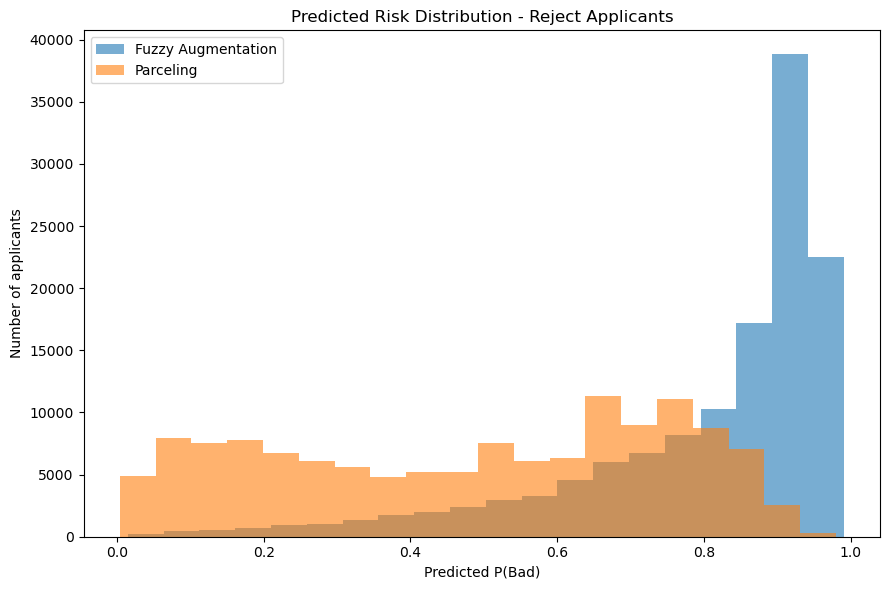

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.hist(
    reject_results["Fuzzy_P_Bad"],
    bins=20,
    alpha=0.6,
    label="Fuzzy Augmentation"
)

plt.hist(
    reject_results["Parceling_P_Bad"],
    bins=20,
    alpha=0.6,
    label="Parceling"
)

plt.xlabel("Predicted P(Bad)")
plt.ylabel("Number of applicants")
plt.title(
    "Predicted Risk Distribution - Reject Applicants"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "RI_reject_probability_distribution.png",
    dpi=300
)

plt.show()

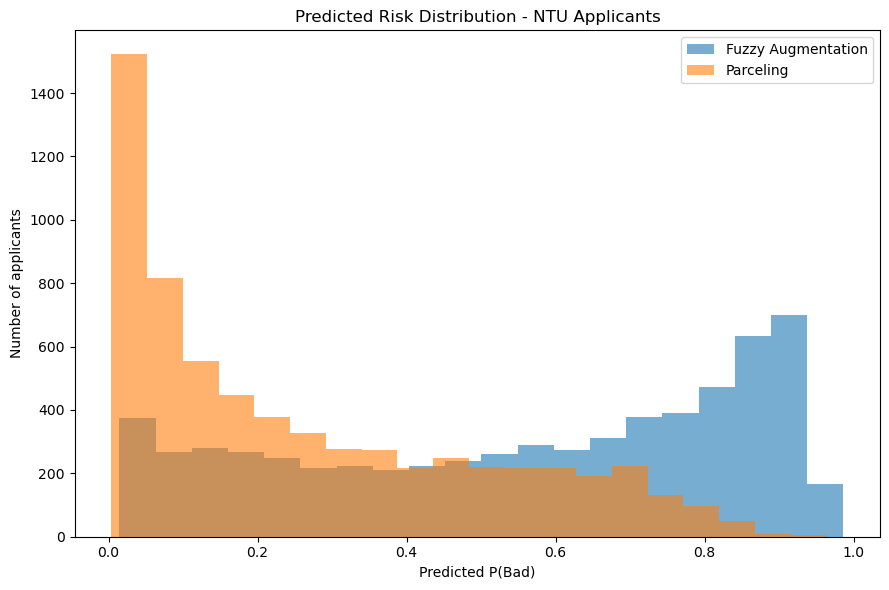

In [28]:
plt.figure(figsize=(9, 6))

plt.hist(
    ntu_results["Fuzzy_P_Bad"],
    bins=20,
    alpha=0.6,
    label="Fuzzy Augmentation"
)

plt.hist(
    ntu_results["Parceling_P_Bad"],
    bins=20,
    alpha=0.6,
    label="Parceling"
)

plt.xlabel("Predicted P(Bad)")
plt.ylabel("Number of applicants")
plt.title(
    "Predicted Risk Distribution - NTU Applicants"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "RI_ntu_probability_distribution.png",
    dpi=300
)

plt.show()

# Risk Band graphs

In [29]:
# ==========================================================
# RISK-BAND DISTRIBUTION FUNCTION
# ==========================================================

def risk_band_percentages(df):

    fuzzy_pct = (
        df["Fuzzy_Risk_Band"]
        .value_counts(normalize=True)
        .reindex(risk_labels, fill_value=0)
        * 100
    )

    parcel_pct = (
        df["Parceling_Risk_Band"]
        .value_counts(normalize=True)
        .reindex(risk_labels, fill_value=0)
        * 100
    )

    return fuzzy_pct, parcel_pct

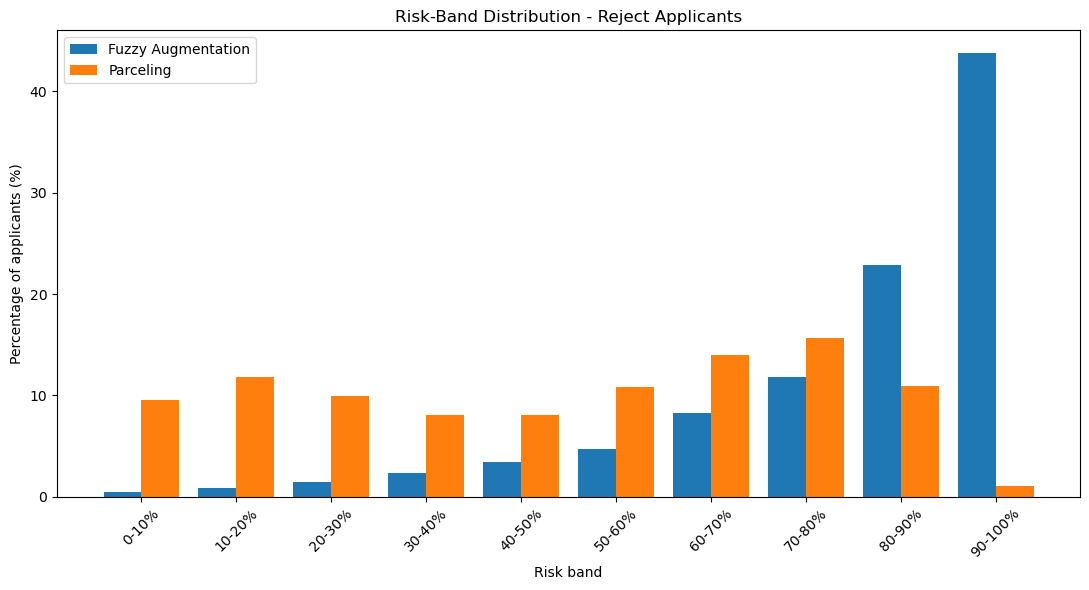

In [30]:
fuzzy_reject_pct, parcel_reject_pct = (
    risk_band_percentages(
        reject_results
    )
)

plt.figure(figsize=(11, 6))

x = np.arange(
    len(risk_labels)
)

width = 0.4

plt.bar(
    x - width / 2,
    fuzzy_reject_pct.values,
    width,
    label="Fuzzy Augmentation"
)

plt.bar(
    x + width / 2,
    parcel_reject_pct.values,
    width,
    label="Parceling"
)

plt.xticks(
    x,
    risk_labels,
    rotation=45
)

plt.xlabel("Risk band")
plt.ylabel("Percentage of applicants (%)")

plt.title(
    "Risk-Band Distribution - Reject Applicants"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "RI_reject_risk_bands.png",
    dpi=300
)

plt.show()

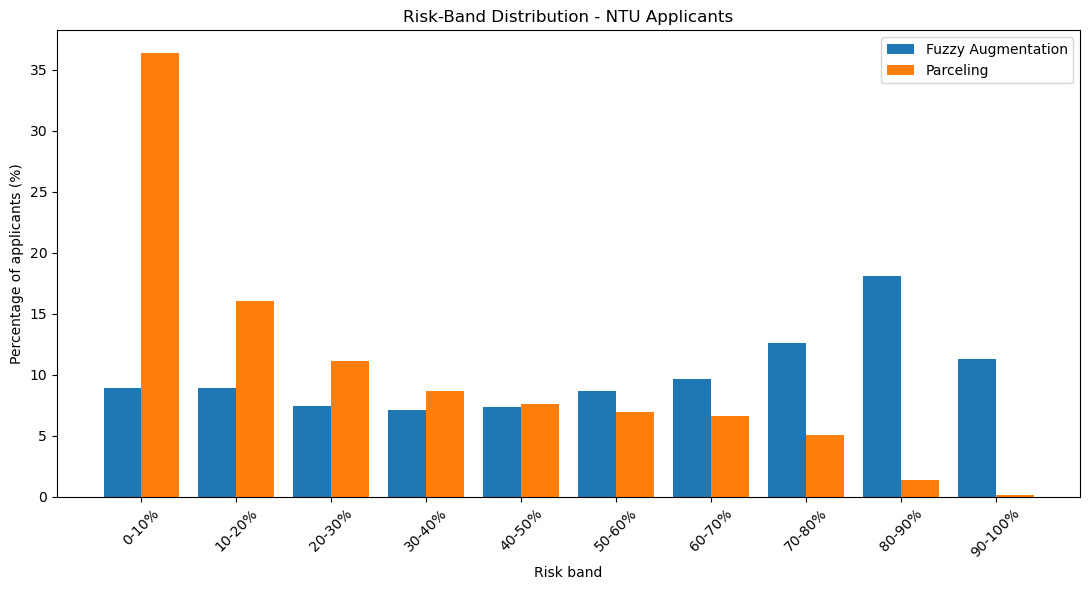

In [31]:
fuzzy_ntu_pct, parcel_ntu_pct = (
    risk_band_percentages(
        ntu_results
    )
)

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    fuzzy_ntu_pct.values,
    width,
    label="Fuzzy Augmentation"
)

plt.bar(
    x + width / 2,
    parcel_ntu_pct.values,
    width,
    label="Parceling"
)

plt.xticks(
    x,
    risk_labels,
    rotation=45
)

plt.xlabel("Risk band")
plt.ylabel("Percentage of applicants (%)")

plt.title(
    "Risk-Band Distribution - NTU Applicants"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "RI_ntu_risk_bands.png",
    dpi=300
)

plt.show()

# Fuzzy vs Parceling scatter plot - how much do the 2 methods disagree?

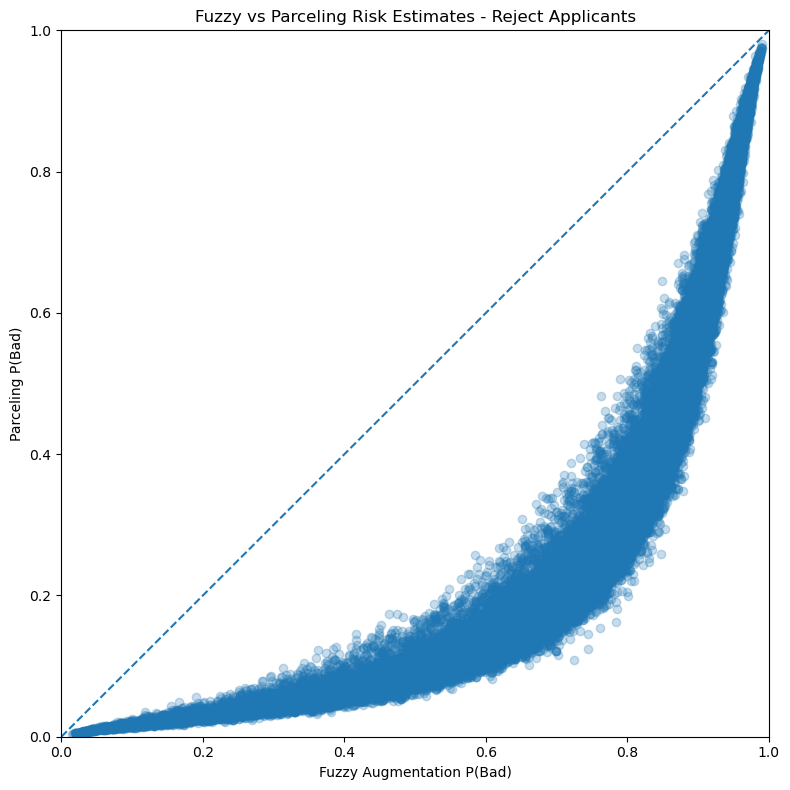

In [32]:
# ==========================================================
# FUZZY VS PARCELING SCATTER PLOT - REJECTS
# ==========================================================

plt.figure(figsize=(8, 8))

plt.scatter(
    reject_results["Fuzzy_P_Bad"],
    reject_results["Parceling_P_Bad"],
    alpha=0.25
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "Fuzzy Augmentation P(Bad)"
)

plt.ylabel(
    "Parceling P(Bad)"
)

plt.title(
    "Fuzzy vs Parceling Risk Estimates - Reject Applicants"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(
    "RI_reject_fuzzy_vs_parceling.png",
    dpi=300
)

plt.show()

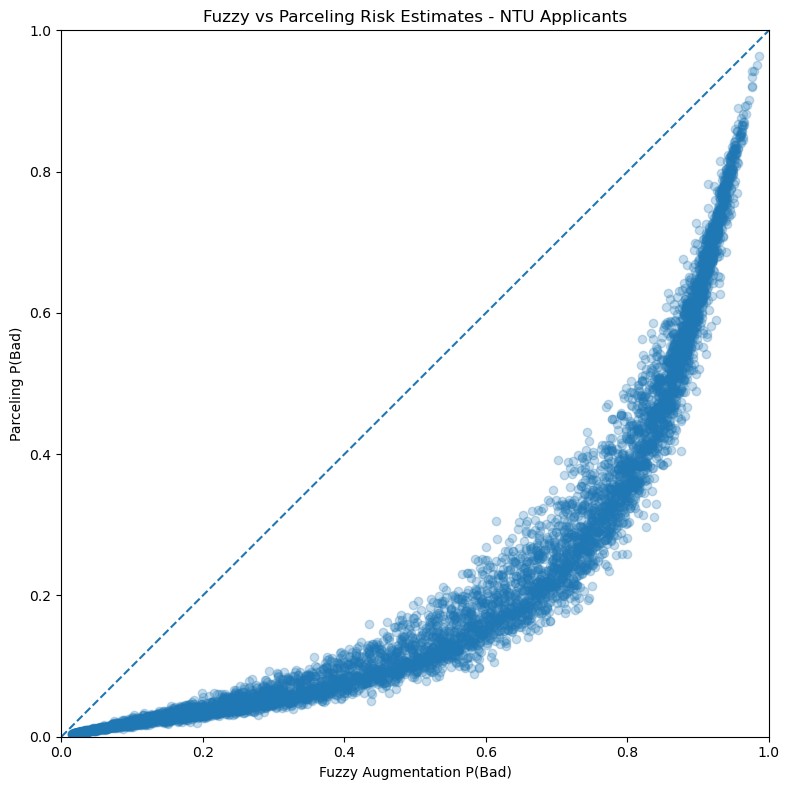

In [33]:
plt.figure(figsize=(8, 8))

plt.scatter(
    ntu_results["Fuzzy_P_Bad"],
    ntu_results["Parceling_P_Bad"],
    alpha=0.25
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "Fuzzy Augmentation P(Bad)"
)

plt.ylabel(
    "Parceling P(Bad)"
)

plt.title(
    "Fuzzy vs Parceling Risk Estimates - NTU Applicants"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(
    "RI_ntu_fuzzy_vs_parceling.png",
    dpi=300
)

plt.show()

# Difference distribution

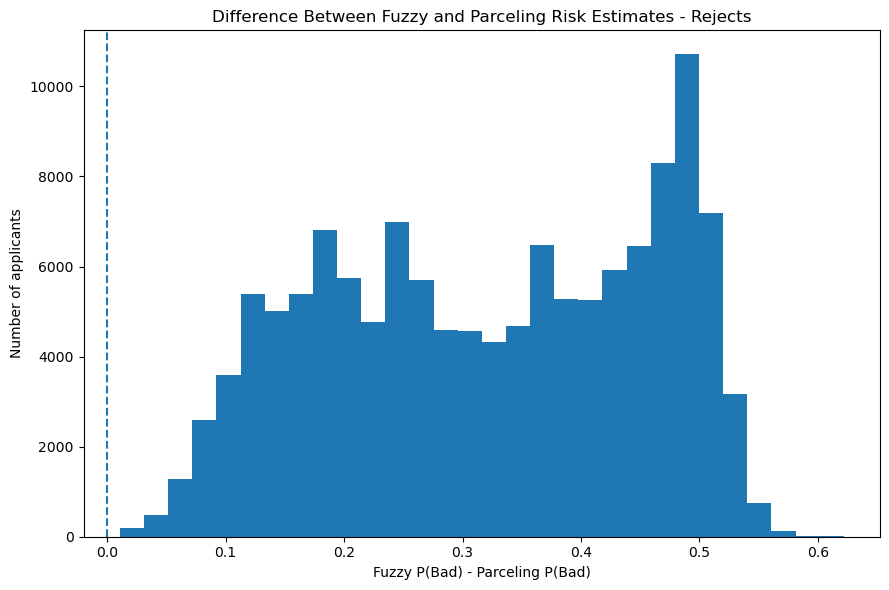

In [34]:
# ==========================================================
# DIFFERENCE DISTRIBUTION - REJECTS
# ==========================================================

plt.figure(figsize=(9, 6))

plt.hist(
    reject_results["Difference"],
    bins=30
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Fuzzy P(Bad) - Parceling P(Bad)"
)

plt.ylabel(
    "Number of applicants"
)

plt.title(
    "Difference Between Fuzzy and Parceling Risk Estimates - Rejects"
)

plt.tight_layout()

plt.savefig(
    "RI_reject_difference_distribution.png",
    dpi=300
)

plt.show()

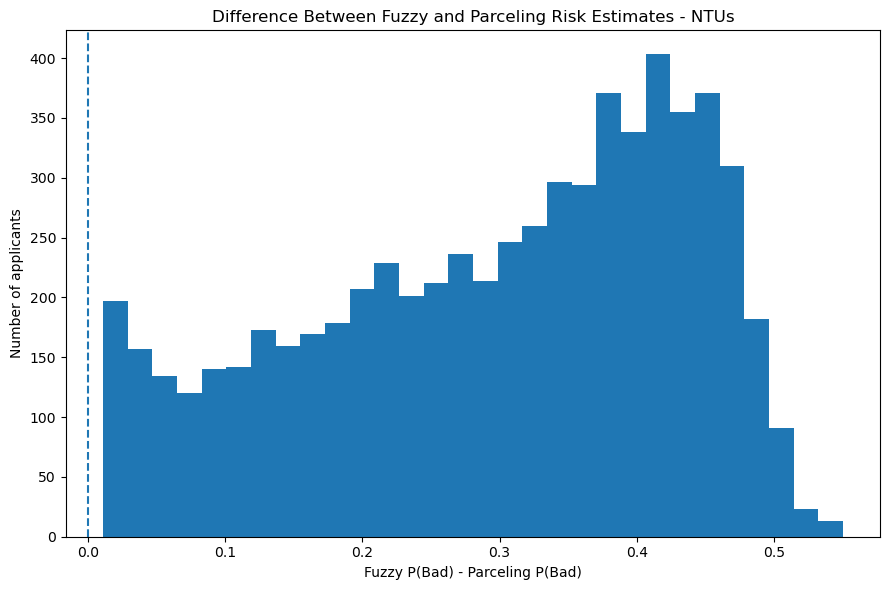

In [35]:
plt.figure(figsize=(9, 6))

plt.hist(
    ntu_results["Difference"],
    bins=30
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Fuzzy P(Bad) - Parceling P(Bad)"
)

plt.ylabel(
    "Number of applicants"
)

plt.title(
    "Difference Between Fuzzy and Parceling Risk Estimates - NTUs"
)

plt.tight_layout()

plt.savefig(
    "RI_ntu_difference_distribution.png",
    dpi=300
)

plt.show()

# Business decision comparison

In [36]:
# ==========================================================
# BUSINESS DECISION COMPARISON
# ==========================================================

def decision_summary(df, threshold):

    fuzzy_accept = (
        df["Fuzzy_P_Bad"] < threshold
    )

    parcel_accept = (
        df["Parceling_P_Bad"] < threshold
    )

    both_accept = (
        fuzzy_accept
        &
        parcel_accept
    )

    both_high_risk = (
        (~fuzzy_accept)
        &
        (~parcel_accept)
    )

    fuzzy_only = (
        fuzzy_accept
        &
        (~parcel_accept)
    )

    parcel_only = (
        (~fuzzy_accept)
        &
        parcel_accept
    )

    return {
        "Threshold": threshold,

        "Fuzzy_accept_%":
            fuzzy_accept.mean() * 100,

        "Parceling_accept_%":
            parcel_accept.mean() * 100,

        "Both_accept_%":
            both_accept.mean() * 100,

        "Both_high_risk_%":
            both_high_risk.mean() * 100,

        "Fuzzy_accept_Parceling_high_%":
            fuzzy_only.mean() * 100,

        "Fuzzy_high_Parceling_accept_%":
            parcel_only.mean() * 100
    }

In [37]:
thresholds = [
    0.30,
    0.50,
    0.70
]

reject_decisions = pd.DataFrame([
    decision_summary(
        reject_results,
        threshold
    )
    for threshold in thresholds
])

ntu_decisions = pd.DataFrame([
    decision_summary(
        ntu_results,
        threshold
    )
    for threshold in thresholds
])

print("REJECT DECISIONS")
display(reject_decisions)

print("NTU DECISIONS")
display(ntu_decisions)

REJECT DECISIONS


,Threshold,Fuzzy_accept_%,Parceling_accept_%,Both_accept_%,Both_high_risk_%,Fuzzy_accept_Parceling_high_%,Fuzzy_high_Parceling_accept_%
0,0.3,2.749738,31.305120,2.749738,68.694880,0.0,28.555382
1,0.5,8.467797,47.445316,8.467797,52.554684,0.0,38.977519
2,0.7,21.461315,72.304528,21.461315,27.695472,0.0,50.843213


NTU DECISIONS


,Threshold,Fuzzy_accept_%,Parceling_accept_%,Both_accept_%,Both_high_risk_%,Fuzzy_accept_Parceling_high_%,Fuzzy_high_Parceling_accept_%
0,0.3,25.256929,63.656182,25.256929,36.343818,0.0,38.399253
1,0.5,39.691685,79.912800,39.691685,20.087200,0.0,40.221115
2,0.7,58.003737,93.413267,58.003737,6.586733,0.0,35.409530


# Summary

In [38]:
# ==========================================================
# SUMMARY STATISTICS
# ==========================================================

def ri_summary(df):

    return pd.Series({

        "Fuzzy_Mean":
            df["Fuzzy_P_Bad"].mean(),

        "Fuzzy_Median":
            df["Fuzzy_P_Bad"].median(),

        "Fuzzy_Std":
            df["Fuzzy_P_Bad"].std(),

        "Parceling_Mean":
            df["Parceling_P_Bad"].mean(),

        "Parceling_Median":
            df["Parceling_P_Bad"].median(),

        "Parceling_Std":
            df["Parceling_P_Bad"].std(),

        "Mean_Absolute_Difference":
            np.abs(
                df["Difference"]
            ).mean(),

        "Mean_Signed_Difference":
            df["Difference"].mean()
    })


summary_table = pd.DataFrame({

    "Reject": ri_summary(
        reject_results
    ),

    "NTU": ri_summary(
        ntu_results
    )

}).T

display(
    summary_table
)

,Fuzzy_Mean,Fuzzy_Median,Fuzzy_Std,Parceling_Mean,Parceling_Median,Parceling_Std,Mean_Absolute_Difference,Mean_Signed_Difference
Reject,0.805387,0.885528,0.183020,0.483616,0.521617,0.264751,0.321771,0.321771
NTU,0.559061,0.617531,0.293384,0.261710,0.180409,0.236827,0.297351,0.297351


# Is there correlation between the ranking for both methods?

In [39]:
# ==========================================================
# CORRELATION
# ==========================================================

reject_corr = reject_results[
    [
        "Fuzzy_P_Bad",
        "Parceling_P_Bad"
    ]
].corr().iloc[0, 1]

ntu_corr = ntu_results[
    [
        "Fuzzy_P_Bad",
        "Parceling_P_Bad"
    ]
].corr().iloc[0, 1]

print(
    f"Reject Fuzzy vs Parceling correlation: "
    f"{reject_corr:.4f}"
)

print(
    f"NTU Fuzzy vs Parceling correlation: "
    f"{ntu_corr:.4f}"
)

Reject Fuzzy vs Parceling correlation: 0.8762
NTU Fuzzy vs Parceling correlation: 0.8890
